In [ ]:
import numpy as np
import plotly.graph_objects as go
import torch
from plotly.express.colors import sequential
import matplotlib.pyplot as plt
import torch
import numpy as np
import deepxde as dde
from deepxde.callbacks import PDEPointResampler, Callback  
import time
file_path = rf'C:\Users\marcschw\Downloads\Hooke_hole-coupled-4-2.csv'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Forces
N1 = 4 # Force on right boundary
N2 = 2 # Force on top boundary
# Quadratic plate length
L = 1.0
# Circle radius
R = 0.10
# Lame constants
MU = 10.0
LAMBDA = 20.0
# Elliptical axis in x direction
Rx = 0.1
Ry = 0.1
# Scaling factor
X = 2
# Edge samples
N = 50 * X
# Number of collocation points
M = 500 * X**2
# Epochs
EPOCHS = 200000
# Learning rate
LR = 0.001
# Gain parameter for initialization
GAIN = 0.5
# Scheduler step width
STEP = 5000
# Gamma factor of scheduler
GAMMA = 0.975
# Number of hidden neurons
HN = 50
# Number of hidden layers
LAYERS = 5
# Fourier features
FEATURES = 100
# Weight of PDE loss
W_PDE = 1.0
# Weight of Dirichlet loss
W_DIR = 1.0
# Weight of Neumann loss
W_NEU = 1.0
# Weight of hole loss
W_HOLE = 1.0
# Weight update factor
ALPHA = 0.9
# Variance
SIGMA = 1.0
# precision
DTYPE = torch.float32

# Weights
#W_PDE_x, W_PDE_y, W_Ux, W_Uy, W_right_sxx, W_right_sxy, W_top_syy, W_top_sxy, W_left_sxy, W_bottom_sxy, W_hole_tx, W_hole_ty = 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0 # PDE x, PDE y, ux_left, uy_bottom, right_sxx, right_sxy, top_syy, top_sxy, left_sxy, bottom_sxy, hole_tx, hole_ty

#Weights from a previous PyTorch run: 
W_DIR=1.61e+05 
W_NEU=1.96e+02
W_PDE=1.09e+00 
W_HOLE=1.85e+01

W_Ux = W_DIR/2
W_left_sxy = W_NEU/6
W_Uy = W_DIR/2
W_bottom_sxy = W_NEU/6
W_top_syy = W_NEU/6
W_top_sxy = W_NEU/6
W_right_sxx = W_NEU/6
W_right_sxy = W_NEU/6
W_hole_tx = W_HOLE/2
W_hole_ty = W_HOLE/2
W_PDE_x = W_PDE/2
W_PDE_y = W_PDE/2
initial_weights = [W_PDE_x, W_PDE_y, W_Ux, W_Uy, W_right_sxx, W_right_sxy, W_top_syy, W_top_sxy, W_left_sxy, W_bottom_sxy, W_hole_tx, W_hole_ty]

# Geometry
rect = dde.geometry.Rectangle([0, 0], [L, L])
circle = dde.geometry.Disk([0, 0], R)
geom = dde.geometry.CSGDifference(rect, circle)

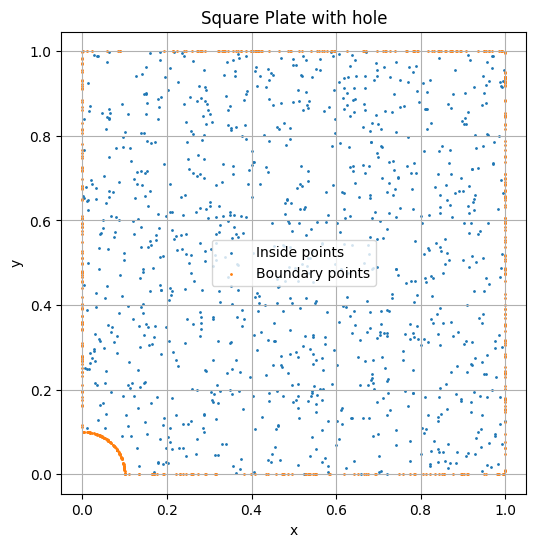

In [ ]:
points = geom.random_points(1000)  # Random points inside the geometry
boundary_points = geom.random_boundary_points(500)  # Points on the boundary

# Plot the points
plt.figure(figsize=(6, 6))
plt.scatter(points[:, 0], points[:, 1], s=1, label="Inside points")
plt.scatter(boundary_points[:, 0], boundary_points[:, 1], s=1, label="Boundary points")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Square Plate with hole")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

In [16]:
# work in progress...Weight updater does not work with deepxde yet
'''
class EpochTimer(Callback):
    def __init__(self):
        super().__init__()
        self.start_time = None
        self.epoch_times = []
        self.avg_epoch_time = 0
        self.epochs_per_second = 0
        
    def on_train_begin(self):
        self.start_time = time.time()
        
    def on_epoch_end(self):
        current_time = time.time()
        if len(self.epoch_times) > 0:
            epoch_time = current_time - (self.start_time + sum(self.epoch_times))
        else:
            epoch_time = current_time - self.start_time
        self.epoch_times.append(epoch_time)
        
        # Calculate metrics
        self.avg_epoch_time = sum(self.epoch_times) / len(self.epoch_times)
        self.epochs_per_second = 1 / self.avg_epoch_time if self.avg_epoch_time > 0 else 0
        
        if self.model.train_state.iteration % 50 == 0:
            remaining_time = (EPOCHS - self.model.train_state.iteration) * self.avg_epoch_time
            print(f"\nEpoch {self.model.train_state.iteration}:")
            print(f"Current epoch time: {epoch_time:.4f}s")
            print(f"Average epoch time: {self.avg_epoch_time:.4f}s")
            print(f"Epochs per second: {self.epochs_per_second:.2f}")
            print(f"Estimated remaining time: {remaining_time/60:.2f} minutes")

# Add to your callbacks
epoch_timer = EpochTimer()

class WeightUpdater_Gradient(Callback):
    def __init__(self, initial_weights):
        super().__init__()
        self.weights = initial_weights
        
    def _update_weight(self, weight, grad_sum, norm):
        new_weight = grad_sum / norm
        return ALPHA * weight + (1 - ALPHA) * new_weight

    def _compute_gradient_norm(self, loss):
        grads = torch.autograd.grad(loss, self.model.net.parameters(), allow_unused=True)
        return sum(0 if grad is None else torch.linalg.norm(grad) for grad in grads)
    
    def on_epoch_end(self):
        eps = 1e-8
        if self.model.train_state.iteration % 100 == 0:
            losses = self.model.train_state.loss_train
            loss_tensors = torch.tensor(losses, dtype=DTYPE, requires_grad=True)
            
            # Calculate gradients and clamp with eps
            grad_W_PDE_x = max(self._compute_gradient_norm(loss_tensors[0]), eps)
            grad_W_PDE_y = max(self._compute_gradient_norm(loss_tensors[1]), eps)
            grad_Ux = max(self._compute_gradient_norm(loss_tensors[2]), eps)
            grad_Uy = max(self._compute_gradient_norm(loss_tensors[3]), eps)
            grad_right_sxx = max(self._compute_gradient_norm(loss_tensors[4]), eps)
            grad_right_sxy = max(self._compute_gradient_norm(loss_tensors[5]), eps)
            grad_top_syy = max(self._compute_gradient_norm(loss_tensors[6]), eps)
            grad_top_sxy = max(self._compute_gradient_norm(loss_tensors[7]), eps)
            grad_left_sxy = max(self._compute_gradient_norm(loss_tensors[8]), eps)
            grad_bottom_sxy = max(self._compute_gradient_norm(loss_tensors[9]), eps)
            grad_hole_tx = max(self._compute_gradient_norm(loss_tensors[10]), eps)
            grad_hole_ty = max(self._compute_gradient_norm(loss_tensors[11]), eps)
            
            grad_sum = grad_W_PDE_x + grad_W_PDE_y + grad_Ux + grad_Uy + \
                      grad_right_sxx + grad_right_sxy + \
                      grad_top_syy + grad_top_sxy + \
                      grad_left_sxy + grad_bottom_sxy + \
                      grad_hole_tx + grad_hole_ty
            
            print(grad_sum)
            
            # Update weights
            self.weights[0] = self._update_weight(self.weights[0], grad_sum, grad_W_PDE_x)
            self.weights[1] = self._update_weight(self.weights[1], grad_sum, grad_W_PDE_y)
            self.weights[2] = self._update_weight(self.weights[2], grad_sum, grad_Ux)
            self.weights[3] = self._update_weight(self.weights[3], grad_sum, grad_Uy)
            self.weights[4] = self._update_weight(self.weights[4], grad_sum, grad_right_sxx)
            self.weights[5] = self._update_weight(self.weights[5], grad_sum, grad_right_sxy)
            self.weights[6] = self._update_weight(self.weights[6], grad_sum, grad_top_syy)
            self.weights[7] = self._update_weight(self.weights[7], grad_sum, grad_top_sxy)
            self.weights[8] = self._update_weight(self.weights[8], grad_sum, grad_left_sxy)
            self.weights[9] = self._update_weight(self.weights[9], grad_sum, grad_bottom_sxy)
            self.weights[10] = self._update_weight(self.weights[10], grad_sum, grad_hole_tx)
            self.weights[11] = self._update_weight(self.weights[11], grad_sum, grad_hole_ty)
            

            if self.weights[0] == self.weights[1] == self.weights[2]:
                print("Funktioniert nicht richtig")

WeightUpdater_Gradient = WeightUpdater_Gradient(initial_weights)

class WeightUpdater_Sum(Callback):
    def __init__(self, initial_weights):
        super().__init__()
        self.weights = initial_weights

    def update_weight(self, weight, grad_sum, norm):
        new_weight = grad_sum / norm
        return ALPHA * weight + (1 - ALPHA) * new_weight
        
    def on_epoch_end(self):
        if self.model.train_state.iteration % 100 == 0:
            # Get the current losses from the model's loss history
            losses = self.model.train_state.loss_train
            total_loss = sum(losses)

            for i in range(len(self.weights)):              
                self.weights[i] = self.update_weight(self.weights[i], total_loss, losses[i])
                
            # Update the model's loss weights
            self.model.loss_weights = self.weights

WeightUpdater_Sum = WeightUpdater_Sum(initial_weights)

class WeightPrinter(Callback):
    def __init__(self, print_interval=1000):
        super().__init__()
        self.print_interval = print_interval
        
    def on_epoch_end(self):
        if self.model.train_state.iteration % self.print_interval == 0:
            # Get the current weights from the model
            weights = self.model.loss_weights
            
            print(f"\nEpoch {self.model.train_state.iteration}: Current weights")
            print(f"W_PDE_x: {weights[0]:.6f}")
            print(f"W_PDE_y: {weights[1]:.6f}")
            print(f"W_Ux: {weights[2]:.6f}")
            print(f"W_Uy: {weights[3]:.6f}")
            print(f"W_right_sxx: {weights[4]:.6f}")
            print(f"W_right_sxy: {weights[5]:.6f}")
            print(f"W_top_syy: {weights[6]:.6f}")
            print(f"W_top_sxy: {weights[7]:.6f}")
            print(f"W_left_sxy: {weights[8]:.6f}")
            print(f"W_bottom_sxy: {weights[9]:.6f}")
            print(f"W_hole_tx: {weights[10]:.6f}")
            print(f"W_hole_ty: {weights[11]:.6f}")

'''

'\nclass EpochTimer(Callback):\n    def __init__(self):\n        super().__init__()\n        self.start_time = None\n        self.epoch_times = []\n        self.avg_epoch_time = 0\n        self.epochs_per_second = 0\n\n    def on_train_begin(self):\n        self.start_time = time.time()\n\n    def on_epoch_end(self):\n        current_time = time.time()\n        if len(self.epoch_times) > 0:\n            epoch_time = current_time - (self.start_time + sum(self.epoch_times))\n        else:\n            epoch_time = current_time - self.start_time\n        self.epoch_times.append(epoch_time)\n\n        # Calculate metrics\n        self.avg_epoch_time = sum(self.epoch_times) / len(self.epoch_times)\n        self.epochs_per_second = 1 / self.avg_epoch_time if self.avg_epoch_time > 0 else 0\n\n        if self.model.train_state.iteration % 50 == 0:\n            remaining_time = (EPOCHS - self.model.train_state.iteration) * self.avg_epoch_time\n            print(f"\nEpoch {self.model.train_state

In [ ]:
# Neo-Hookean material model functions
# x: input tensor, y: displacement output tensor [u, v]
def deformation_gradient(x, y):
    u = y[:, 0:1]  # x-displacement
    v = y[:, 1:2]  # y-displacement
    
    du_dx = dde.grad.jacobian(y, x, i=0, j=0)
    du_dy = dde.grad.jacobian(y, x, i=0, j=1)
    dv_dx = dde.grad.jacobian(y, x, i=1, j=0)
    dv_dy = dde.grad.jacobian(y, x, i=1, j=1)
    
    F11 = 1 + du_dx
    F12 = du_dy
    F21 = dv_dx
    F22 = 1 + dv_dy
    
    return F11, F12, F21, F22

def first_piola_kirchhoff_stress(x, y):
    F11, F12, F21, F22 = deformation_gradient(x, y)
    
    J = F11 * F22 - F12 * F21
    FinvT11 = F22 / J # Inverse transpose of F11
    FinvT12 = -F12 / J
    FinvT21 = -F21 / J
    FinvT22 = F11 / J
    
    P11 = MU * F11 + (LAMBDA * torch.log(J) - MU) * FinvT11
    P12 = MU * F12 + (LAMBDA * torch.log(J) - MU) * FinvT21
    P21 = MU * F21 + (LAMBDA * torch.log(J) - MU) * FinvT12
    P22 = MU * F22 + (LAMBDA * torch.log(J) - MU) * FinvT22
    
    return P11, P12, P21, P22

def pde(x, y):
    P11, P12, P21, P22 = first_piola_kirchhoff_stress(x, y)
    
    # Compute gradients of P components
    dP11_dx = dde.grad.jacobian(P11, x, i=0, j=0)
    dP12_dy = dde.grad.jacobian(P12, x, i=0, j=1)
    dP21_dx = dde.grad.jacobian(P21, x, i=0, j=0)
    dP22_dy = dde.grad.jacobian(P22, x, i=0, j=1)
    
    residual_x = dP11_dx + dP12_dy
    residual_y = dP21_dx + dP22_dy
    
    return [residual_x, residual_y]

def sigma(x, y):
    F11, F12, F21, F22 = deformation_gradient(x, y)
    J = F11 * F22 - F12 * F21
    
    P11, P12, P21, P22 = first_piola_kirchhoff_stress(x, y)
    
    sigma_xx = (P11 * F11 + P12 * F12) / J
    sigma_xy = (P11 * F21 + P12 * F22) / J
    sigma_yx = (P21 * F11 + P22 * F12) / J  
    sigma_yy = (P21 * F21 + P22 * F22) / J
    
    return sigma_xx, sigma_xy, sigma_yx, sigma_yy

In [18]:
# Boundary conditions
def left_boundary(x, on_boundary):
    return on_boundary and dde.utils.isclose(x[0], 0) and (x[1] >= R)

def bottom_boundary(x, on_boundary):
    return on_boundary and dde.utils.isclose(x[1], 0) and (x[0] >= R)

def right_boundary(x, on_boundary):
    return on_boundary and dde.utils.isclose(x[0], L)

def top_boundary(x, on_boundary):
    return on_boundary and dde.utils.isclose(x[1], L)

def hole_boundary(x, on_boundary):
    return on_boundary and dde.utils.isclose(np.linalg.norm(x), R)

# Displacement BCs
ux_left_bc = dde.icbc.DirichletBC(geom, lambda x: 0, left_boundary, component=0)
uy_bottom_bc = dde.icbc.DirichletBC(geom, lambda x: 0, bottom_boundary, component=1)

# Stress BCs
def right_stress_x(x, y, _):
    P11, _, _, _ = first_piola_kirchhoff_stress(x, y)
    return P11 - N1

def right_stress_xy(x, y, _):
    _, P12, _, _ = first_piola_kirchhoff_stress(x, y)
    return P12

def top_stress_y(x, y, _):
    _, _, _, P22 = first_piola_kirchhoff_stress(x, y)
    return P22 - N2

def top_stress_xy(x, y, _):
    _, P12, _, _ = first_piola_kirchhoff_stress(x, y)
    return P12

def left_stress_xy(x, y, _):
    _, _, P21, _ = first_piola_kirchhoff_stress(x, y)
    return P21

def bottom_stress_xy(x, y, _):
    _, _, P21, _ = first_piola_kirchhoff_stress(x, y)
    return P21

def hole_traction_x(x, y, _):
    P11, P12, _, _ = first_piola_kirchhoff_stress(x, y)
    nx = x[:, 0:1] / R  # normal x component
    ny = x[:, 1:2] / R  # normal y component
    return P11 * nx + P12 * ny

def hole_traction_y(x, y, _):
    _, _, P21, P22 = first_piola_kirchhoff_stress(x, y)
    nx = x[:, 0:1] / R  # normal x component
    ny = x[:, 1:2] / R  # normal y component
    return P21 * nx + P22 * ny

#OperatorBCs
right_sxx_bc = dde.icbc.OperatorBC(geom, right_stress_x, right_boundary)
right_sxy_bc = dde.icbc.OperatorBC(geom, right_stress_xy, right_boundary)
top_syy_bc = dde.icbc.OperatorBC(geom, top_stress_y, top_boundary)
top_sxy_bc = dde.icbc.OperatorBC(geom, top_stress_xy, top_boundary)
left_sxy_bc = dde.icbc.OperatorBC(geom, left_stress_xy, left_boundary)
bottom_sxy_bc = dde.icbc.OperatorBC(geom, bottom_stress_xy, bottom_boundary)
hole_tx_bc = dde.icbc.OperatorBC(geom, hole_traction_x, hole_boundary)
hole_ty_bc = dde.icbc.OperatorBC(geom, hole_traction_y, hole_boundary)

In [19]:
class CustomNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Input layer
        self.layers = torch.nn.ModuleList(
            [torch.nn.Linear(2 * FEATURES, HN).type(DTYPE)]
        )
        # Hidden layers
        for _ in range(LAYERS - 1):
            self.layers.append(torch.nn.Linear(HN, HN).type(DTYPE))
        # Output layer
        self.output_layer = torch.nn.Linear(HN, 2).type(DTYPE)

        # Initialize weights
        for layer in self.layers:
            torch.nn.init.xavier_uniform_(layer.weight, gain=GAIN)

        torch.nn.init.xavier_uniform_(self.output_layer.weight, gain=GAIN)

        # Sample B from normal distribution
        self.register_buffer("B", torch.normal(0.0, SIGMA, size=(2, FEATURES), dtype=DTYPE, device=device))
        
        # Required by DeepXDE
        self.regularizer = None

    def forward(self, inputs):
        inputs = torch.as_tensor(inputs, device=device)
            
        # Feature transform
        x = inputs
        x = torch.cat(
            [torch.sin(2 * np.pi * torch.matmul(x, self.B)), 
             torch.cos(2 * np.pi * torch.matmul(x, self.B))],
            dim=-1
        )
        
        # Hidden layers with tanh activation
        for layer in self.layers:
            x = torch.tanh(layer(x))
            
        return self.output_layer(x)

In [ ]:
# Define the PDE problem
data = dde.data.PDE(
    geom,
    pde,
    [ux_left_bc, uy_bottom_bc, 
     right_sxx_bc, right_sxy_bc,
     top_syy_bc, top_sxy_bc,
     left_sxy_bc, bottom_sxy_bc,
     hole_tx_bc, hole_ty_bc],
    num_domain=M,
    num_boundary=N,
    num_test=100,
    train_distribution="LHS" # Latin Hypercube Sampling
)

net = CustomNet()
model = dde.Model(data, net)
model.net.to(device)
#net.load_state_dict(torch.load("model_weights.pth"))

resampler = PDEPointResampler(period=100) # 100 seems to work best with deepxde

# In your model compilation:
model.compile(
    "adam",
    lr=LR,
    decay=("step", STEP, GAMMA),
    loss_weights=initial_weights
)


Compiling model...
'compile' took 0.000168 s



Training model...

Step      Train loss                                                                                                                  Test loss                                                                                                                   Test metric
0         [8.53e+02, 1.17e+03, 8.25e+02, 4.03e+02, 6.90e+02, 7.89e+01, 1.95e+03, 4.66e+01, 3.81e+01, 1.87e+01, 1.82e+01, 2.33e+01]    [8.50e+02, 1.27e+03, 8.25e+02, 4.03e+02, 6.90e+02, 7.89e+01, 1.95e+03, 4.66e+01, 3.81e+01, 1.87e+01, 1.82e+01, 2.33e+01]    []  
1000      [1.12e+00, 2.84e-01, 2.56e-01, 1.50e-01, 2.35e-02, 8.33e-03, 4.86e-03, 1.23e-02, 5.17e-02, 9.13e-02, 2.25e-01, 7.50e-02]    [1.67e+00, 2.29e-01, 2.56e-01, 1.50e-01, 2.35e-02, 8.33e-03, 4.86e-03, 1.23e-02, 5.17e-02, 9.13e-02, 2.25e-01, 7.50e-02]    []  
2000      [6.05e-01, 1.23e-01, 1.51e-01, 1.22e-01, 8.83e-03, 4.27e-03, 1.20e-03, 3.37e-03, 4.58e-02, 1.02e-01, 2.08e-01, 6.90e-02]    [7.95e-01, 5.88e-02, 1.51e-01, 1.22e-01, 8.83e-03, 

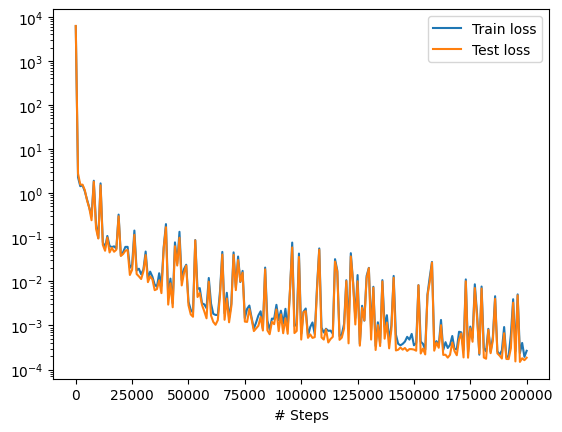

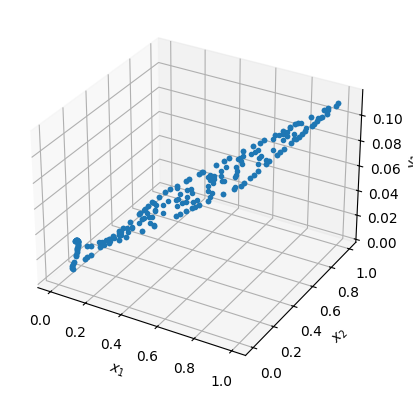

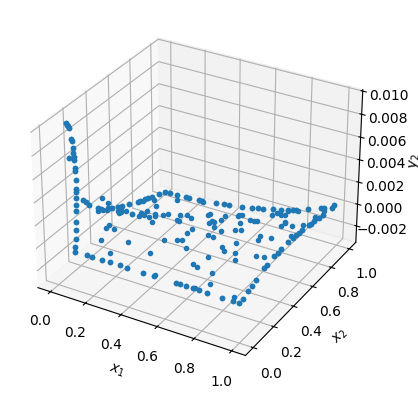

In [ ]:
# Modify your train call to include the timer

losshistory, train_state = model.train(
    iterations=EPOCHS,
    display_every=2000,
    callbacks=[
        resampler, 
    ]
)

dde.saveplot(model.losshistory, model.train_state, issave=True, isplot=True)
#torch.save(model.state_dict(), "model_weights_DEEPXDE_Test1.pth")


In [22]:
# Load reference data
csv_data = np.loadtxt(file_path, delimiter=',', skiprows=1)
csv_x = csv_data[:, 0]
csv_y = csv_data[:, 1]
csv_val = np.vstack([csv_x, csv_y]).T
csv_sx = csv_data[:, 2]
csv_sy = csv_data[:, 3]
csv_sxy = csv_data[:, 4]
csv_disp_x = csv_data[:, 8]
csv_disp_y = csv_data[:, 9]
csv_piola1_x = csv_data[:, 10]
csv_piola1_y = csv_data[:, 11]
csv_piola1_xy = csv_data[:, 12]
csv_piola2_x = csv_data[:, 13]
csv_piola2_y = csv_data[:, 14]
csv_piola2_xy = csv_data[:, 15]

# Use CSV data as validation domain
csv_val = np.vstack([csv_x, csv_y]).T

# Compute model predictions on the validation domain (CSV points)
disp = model.predict(csv_val)

@torch.no_grad()
def make_plot(x, y, variable, title, cmap=sequential.Viridis, size=18.0):
    fig = go.Figure()
    
    # Create points along each boundary
    # Top boundary (y = L, x from 0 to L)
    top_x = np.linspace(0, L, 100)
    top_y = np.full_like(top_x, L)
    top = np.column_stack((top_x, top_y))
    
    # Bottom boundary (y = 0, x from R to L)
    bottom_x = np.linspace(R, L, 100)
    bottom_y = np.zeros_like(bottom_x)
    bottom = np.column_stack((bottom_x, bottom_y))
    
    # Left boundary (x = 0, y from R to L)
    left_y = np.linspace(R, L, 100)
    left_x = np.zeros_like(left_y)
    left = np.column_stack((left_x, left_y))
    
    # Right boundary (x = L, y from 0 to L)
    right_y = np.linspace(0, L, 100)
    right_x = np.full_like(right_y, L)
    right = np.column_stack((right_x, right_y))
    
    # Plot boundaries
    m = dict(color="black")
    fig.add_trace(go.Scatter(
        x=top[:, 0], y=top[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=bottom[:, 0], y=bottom[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=left[:, 0], y=left[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=right[:, 0], y=right[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))

    # Plot variable values with custom hover text
    m = dict(
        color=variable,
        colorscale=cmap,
        size=size,
        colorbar=dict(thickness=25)
    )

    # Convert tensor to numpy if needed
    if isinstance(variable, torch.Tensor):
        variable = variable.cpu().numpy()

    # Create custom hover text
    hover_text = [f"x: {xi:.4f}<br>y: {yi:.4f}<br>Value: {val:.4f}"
                 for xi, yi, val in zip(x, y, variable)]

    fig.add_trace(go.Scatter(
        x=x,
        y=y,
        marker=m,
        mode="markers",
        hovertext=hover_text,
        hoverinfo="text"
    ))

    # Plot settings
    fig.layout.yaxis.scaleanchor = "x"
    fig.update_layout(
        template="none",
        width=1200,
        height=1200,
        title=title,
        showlegend=False,
        hovermode='closest'
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()

# Plot displacements
make_plot(csv_x, csv_y, disp[:, 0], f"Model Displacement in x₁", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_disp_x, "CSV Displacement in x₁", cmap=sequential.Inferno)

make_plot(csv_x, csv_y, disp[:, 1], f"Model Displacement in x₂", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_disp_y, "CSV Displacement in x₂", cmap=sequential.Inferno)

# Compute Cauchy stress at given points
def compute_sigma(points):
    points_tensor = torch.tensor(points, dtype=DTYPE, device=device)
    points_tensor.requires_grad_(True)

    # Get displacement predictions
    displacement = model.net(points_tensor)

    # Compute Cauchy stress components
    sigma_xx, sigma_xy, sigma_yx, sigma_yy = sigma(points_tensor, displacement)

    # Squeeze to remove extra dimensions
    return (
        sigma_xx.detach().cpu().squeeze().numpy(),
        sigma_xy.detach().cpu().squeeze().numpy(),
        sigma_yx.detach().cpu().squeeze().numpy(),
        sigma_yy.detach().cpu().squeeze().numpy()
    )


# Compute at CSV points
sigma_xx, sigma_xy, sigma_yx, sigma_yy = compute_sigma(csv_val)

# Plot Cauchy stress components
make_plot(csv_x, csv_y, sigma_xx, "Model σ_x₁ (Cauchy stress)", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sx, "CSV σ_x₁ (Cauchy stress)", cmap=sequential.Inferno)

make_plot(csv_x, csv_y, sigma_yy, "Model σ_x₂ (Cauchy stress)", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sy, "CSV σ_x₂ (Cauchy stress)", cmap=sequential.Inferno)

make_plot(csv_x, csv_y, sigma_xy, "Model σ_x₁x₂ (Cauchy stress)", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sxy, "CSV σ_x₁x₂ (Cauchy stress)", cmap=sequential.Inferno)


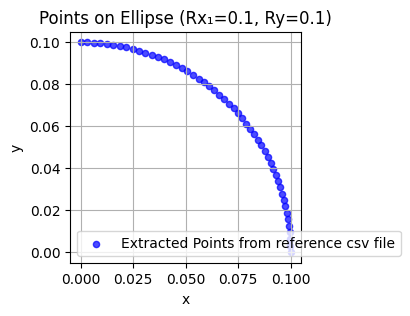

In [ ]:
def reference_data(csv_path):
    data = np.loadtxt(csv_path, delimiter=',', skiprows=1)
    points = data[:, 0:2]        # Columns 0 and 1 (x, y)
    stresses = data[:, 2:5]      # Columns 2, 3, and 4 (stress components) sigma_x, sigma_y, sigma_xy
    strains = data[:, 5:8]       # Columns 5, 6, and 7 (strain components) epsilon_x, epsilon_y, epsilon_xy
    displacements = data[:, 8:10] # Columns 8 and 9 (deformation components) u_x, u_y
    first_piola = data[:, 10:13] # Columns 10, 11, and 12 (first Piola-Kirchhoff stress components) P_x, P_y, P_xy
    second_piola = data[:, 13:16] # Columns 13, 14, and 15 (second Piola-Kirchhoff stress components) S_x, S_y, S_xy

    return (
        points,        
        stresses,       
        strains,        
        displacements,   
        first_piola,    
        second_piola   
    )

ref_points, ref_stresses, ref_strains, ref_displacements, ref_piola1, ref_piola2 = reference_data(file_path)

tol = 0.05 #tolerance

def extract_ellipse_boundary_data(file_path, tol):
    data = np.loadtxt(file_path, delimiter=',', skiprows=1)

    points = data[:, 0:2]  # x, y columns
    x, y = points[:, 0], points[:, 1]

    # Ellipse equation
    mask = np.abs((x**2/Rx**2) + (y**2/Ry**2) - 1) < tol

    return (
        points[mask],     # x and y as numpy array
        data[mask, 2:5]  # stress components sigma_x, sigma_y, sigma_xy as numpy array
    )

# Plotting the extracted points
points, stresspoints = extract_ellipse_boundary_data(file_path, tol=0.05)
plt.figure(figsize=(4, 3))
plt.scatter(points[:, 0], points[:, 1], s=20, color='blue', alpha=0.7, label='Extracted Points from reference csv file')
plt.gca().set_aspect('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Points on Ellipse (Rx₁={Rx:.1f}, Ry={Ry:.1f})')
plt.legend()
plt.grid(True)
plt.show()

# Compute Cauchy stress at given points
def compute_sigma(points):
    points_tensor = torch.tensor(points, dtype=DTYPE, device=device)
    points_tensor.requires_grad_(True)
    
    # Get displacement predictions
    displacement = model.net(points_tensor)
    
    # Compute Cauchy stress
    sigma_xx, sigma_xy, sigma_yx, sigma_yy = sigma(points_tensor, displacement)
    
    # Squeeze to remove extra dimension
    return (
        sigma_xx.detach().cpu().squeeze().numpy(),
        sigma_yy.detach().cpu().squeeze().numpy(),
        sigma_xy.detach().cpu().squeeze().numpy()
    )

sigma_xx, sigma_yy, sigma_xy = compute_sigma(points)

# Extract reference data for hole boundary
points_hole, hole_stress_ref = extract_ellipse_boundary_data(file_path, tol=0.05)

# Convert to numpy (safety check)
if isinstance(points_hole, torch.Tensor):
    points_hole = points_hole.detach().cpu().numpy()
if isinstance(hole_stress_ref, torch.Tensor):
    hole_stress_ref = hole_stress_ref.detach().cpu().numpy()

# Sort by x-coordinate
sort_idx = np.argsort(points_hole[:, 0])
points_hole_sorted = points_hole[sort_idx]
hole_stress_sorted = hole_stress_ref[sort_idx]

# --- Plotting ---
fig = go.Figure()

# Consistent styles
line_width = 3
marker_size = 8

# σ_xx
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=sigma_xx,
        marker=dict(color="blue", size=marker_size),
        mode="markers",
        name="σ_11 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 0],
        line=dict(color="blue", width=line_width),
        mode="lines",
        name="σ_11 (FEM)",
    )
)

# σ_yy
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=sigma_yy,
        marker=dict(color="orange", size=marker_size),
        mode="markers",
        name="σ_22 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 1],
        line=dict(color="orange", width=line_width),
        mode="lines",
        name="σ_22 (FEM)",
    )
)

# σ_xy
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=sigma_xy,
        marker=dict(color="green", size=marker_size),
        mode="markers",
        name="σ_12 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 2],
        line=dict(color="green", width=line_width),
        mode="lines",
        name="σ_12 (FEM)",
    )
)

# Layout (matching your reference)
fig.update_layout(
    template="plotly_white",
    width=1600,
    height=1000,
    title={
        'text': "Stress Components at Hole Boundary",
        'y':0.9,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top',
        'font': dict(size=30)
    },
    xaxis=dict(
        title=dict(
            text="x₁-coordinate along hole boundary",
            font=dict(size=28)
        ),
        tickfont=dict(size=24)
    ),
    yaxis=dict(
        title=dict(
            text="Stress Value",
            font=dict(size=28)
        ),
        tickfont=dict(size=24)
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.05,
        xanchor="center",
        x=0.5,
        itemwidth=80,
        font=dict(size=20)
    ),
    margin=dict(
        l=50,
        r=50,
        b=50,
        t=100,
        pad=4
    ),
    hovermode="x unified"
)

fig.show()

In [25]:
# Load reference data
csv_data = np.loadtxt(file_path, delimiter=',', skiprows=1)
csv_x = csv_data[:, 0]
csv_y = csv_data[:, 1]
csv_val = np.vstack([csv_x, csv_y]).T
csv_sx = csv_data[:, 2]
csv_sy = csv_data[:, 3]
csv_sxy = csv_data[:, 4]
csv_disp_x = csv_data[:, 8]
csv_disp_y = csv_data[:, 9]

# Convert to torch tensors for computation
ref_displacements = torch.tensor(np.column_stack([csv_disp_x, csv_disp_y]), dtype=DTYPE, device=device)
ref_stresses = torch.tensor(np.column_stack([csv_sx, csv_sy, csv_sxy]), dtype=DTYPE, device=device)

# Compute model predictions on the validation domain (CSV points)
disp = model.predict(csv_val)
pred_displacements = torch.tensor(disp, dtype=DTYPE, device=device)

# Compute Cauchy stress at CSV points - handle different return formats
sigma_results = compute_sigma(csv_val)

# Check how many values are returned and handle accordingly
if len(sigma_results) == 4:
    sigma_xx, sigma_xy, sigma_yx, sigma_yy = sigma_results
    pred_stresses = torch.tensor(np.column_stack([sigma_xx, sigma_yy, sigma_xy]), dtype=DTYPE, device=device)
elif len(sigma_results) == 3:
    # If only 3 values returned, they're likely sigma_xx, sigma_yy, sigma_xy
    sigma_xx, sigma_yy, sigma_xy = sigma_results
    pred_stresses = torch.tensor(np.column_stack([sigma_xx, sigma_yy, sigma_xy]), dtype=DTYPE, device=device)
else:
    raise ValueError(f"compute_sigma returned {len(sigma_results)} values, expected 3 or 4")

# Calculate displacement errors
displacement_error_x_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0])) / torch.mean(torch.abs(ref_displacements[:, 0]))
displacement_error_y_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1])) / torch.mean(torch.abs(ref_displacements[:, 1]))

max_disp_error_x = torch.max(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0])).item()
max_disp_error_y = torch.max(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1])).item()

# Calculate stress errors
stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_stresses[:, 0] - ref_stresses[:, 0])) / torch.mean(torch.abs(ref_stresses[:, 0]))
stress_error_yy_wMAPE = 100 * torch.mean(torch.abs(pred_stresses[:, 1] - ref_stresses[:, 1])) / torch.mean(torch.abs(ref_stresses[:, 1]))
stress_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_stresses[:, 2] - ref_stresses[:, 2])) / torch.mean(torch.abs(ref_stresses[:, 2]))

max_stress_error_xx = torch.max(torch.abs(pred_stresses[:, 0] - ref_stresses[:, 0])).item()
max_stress_error_yy = torch.max(torch.abs(pred_stresses[:, 1] - ref_stresses[:, 1])).item()
max_stress_error_xy = torch.max(torch.abs(pred_stresses[:, 2] - ref_stresses[:, 2])).item()

# Print last results
print(f"Displacement wMAPE in x₁: {displacement_error_x_wMAPE:.2f}%       Max Displacement Error in x₁: {max_disp_error_x:.4f}")
print(f"Displacement wMAPE in x₂: {displacement_error_y_wMAPE:.2f}%       Max Displacement Error in x₂: {max_disp_error_y:.4f}")
print("-" * 90)
print(f"Stress wMAPE in x₁: {stress_error_xx_wMAPE:.2f}%       Max Stress Error in x₁: {max_stress_error_xx:.4f}")
print(f"Stress wMAPE in x₂: {stress_error_yy_wMAPE:.2f}%       Max Stress Error in x₂: {max_stress_error_yy:.4f}")
print(f"Stress wMAPE in x₁x₂: {stress_error_xy_wMAPE:.2f}%       Max Stress Error in x₁x₂: {max_stress_error_xy:.4f}")

Displacement wMAPE in x₁: 0.93%       Max Displacement Error in x₁: 0.0024
Displacement wMAPE in x₂: 13.78%       Max Displacement Error in x₂: 0.0012
------------------------------------------------------------------------------------------
Stress wMAPE in x₁: 0.29%       Max Stress Error in x₁: 0.3018
Stress wMAPE in x₂: 1.15%       Max Stress Error in x₂: 0.0980
Stress wMAPE in x₁x₂: 2.40%       Max Stress Error in x₁x₂: 0.0963


In [26]:
# Extract reference data for hole boundary
points_hole, hole_stress_ref = extract_ellipse_boundary_data(file_path, tol=0.05)

# Compute model predictions on hole boundary points
sigma_xx, sigma_yy, sigma_xy = compute_sigma(points_hole)

# Convert to torch tensors for computation
pred_hole_stresses = torch.tensor(np.column_stack([sigma_xx, sigma_yy, sigma_xy]), dtype=DTYPE, device=device)
ref_hole_stresses = torch.tensor(hole_stress_ref, dtype=DTYPE, device=device)

# Calculate hole stress errors
hole_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stresses[:, 0] - ref_hole_stresses[:, 0])) / torch.mean(torch.abs(ref_hole_stresses[:, 0]))
hole_error_yy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stresses[:, 1] - ref_hole_stresses[:, 1])) / torch.mean(torch.abs(ref_hole_stresses[:, 1]))
hole_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stresses[:, 2] - ref_hole_stresses[:, 2])) / torch.mean(torch.abs(ref_hole_stresses[:, 2]))

max_hole_error_xx = torch.max(torch.abs(pred_hole_stresses[:, 0] - ref_hole_stresses[:, 0])).item()
max_hole_error_yy = torch.max(torch.abs(pred_hole_stresses[:, 1] - ref_hole_stresses[:, 1])).item()
max_hole_error_xy = torch.max(torch.abs(pred_hole_stresses[:, 2] - ref_hole_stresses[:, 2])).item()

# Print hole results
print(f"Hole wMAPE in x₁: {hole_error_xx_wMAPE:.2f}%       Max Hole Stress Error in x₁: {max_hole_error_xx:.4f}")
print(f"Hole wMAPE in x₂: {hole_error_yy_wMAPE:.2f}%       Max Hole Stress Error in x₂: {max_hole_error_yy:.4f}")
print(f"Hole wMAPE in x₁x₂: {hole_error_xy_wMAPE:.2f}%       Max Hole Stress Error in x₁x₂: {max_hole_error_xy:.4f}")

Hole wMAPE in x₁: 1.02%       Max Hole Stress Error in x₁: 0.3019
Hole wMAPE in x₂: 1.55%       Max Hole Stress Error in x₂: 0.0624
Hole wMAPE in x₁x₂: 1.40%       Max Hole Stress Error in x₁x₂: 0.0963
